# Galectin analysis, alternative 1: one green blob per image

LipidTOX droplets (red, idx0) · LAMP1-RFP lysosomes (orange, idx1) · galectin-GFP (green, idx2) · Hoechst nuclei (blue, idx3)

This notebook tests a different method from `M17D_4channel_analysis.ipynb` and writes separate outputs, so it can be compared without touching the original.

**Method**
1. **Galectin cells come straight from the green channel.** The original segments cells with Cellpose on orange + red and often cuts one galectin cell into 2–3 pieces, some without a nucleus. Here GFP fills the whole cell, so cells are found with a two-level threshold relative to each image's background. A cell needs a core at least 10× background, which excludes dim speckled low expressors.
2. **Nuclei are counted, not assumed.** Cellpose nuclei labels are used directly, with no intensity union, each trimmed to its own Hoechst signal (Cellpose draws them ~12 px too wide). A nucleus belongs to the green blob that holds ≥70% of it. If a green blob has no nucleus, Cellpose is re-run on log-scaled Hoechst for that blob only, because some transfected cells have a dim nucleus.
3. **Exclusions.** A blob is removed if it has 0 nuclei, 0 cytoplasm (or < 1000 px), touches the image edge, or has no red or no orange.
4. **One row per image.** All kept blobs in an image are merged into one region and measured. The row reports `N_Nuclei` (nuclei inside) and `N_Green_Cells` (blobs), plus per-nucleus and per-area normalised dot counts.
5. **Galectin puncta are detected by contrast, not percentile.** A punctum must peak at ≥2× the surrounding cytoplasm of the same cell and ≥4 robust SDs (MAD) above that cell's texture. Its footprint is the connected area ≥1.5× the cytoplasm. A percentile threshold always flags the top ~15% of pixels, so it counts dim texture in dot-poor cells and misses puncta in dot-rich cells.

**Outputs** (one CSV per image folder, as in the original)
- `Results/<folder>_galectin_alt1_green_blob_per_image.csv`: one row per image.
- `Results/masks_alt1_green_blob/<folder>/<image>/`: masks, `blob_eligibility.csv` (every blob, its measurements and its exclusion reason), and a QC PNG.

All MFIs are from the raw uint16 green channel.

## Imports

In [1]:
%matplotlib inline
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

import czifile
from scipy import ndimage as ndi
from skimage import exposure, morphology
from skimage.feature import blob_log
from skimage.filters import gaussian
from skimage.measure import label, regionprops
from skimage.morphology import remove_small_objects, disk
from skimage.segmentation import relabel_sequential, watershed, find_boundaries

## Parameters

In [2]:
BASE_DIR = "."
IMAGE_FOLDER_NAMES = [
    "galectin test images",
    "M17D_52926_siRNA_galectinGFP_LAMP1RFP_LipidTOXfr_hoechst",
    "M17D_60426_siRNA_galectinGFP_LAMP1RFP_LipidTOXfr_hoechst",
    "M17D_60526_siRNA_OA_Fed_galectinGFP_LAMP1RFP_LipidTOXfr_hoechst",
    "M17D_60926_siRNA_OA_Fed_galectinGFP_LAMP1RFP_LipidTOXfr_Hoechst",
    "M17D_61126_siRNA_galectinGFP_LAMP1RFP_LipidTOXfr_hoechst",
    "M17D_61826_siRNA_galectinGFP_LAMP1RFP_LipidTOXfr_hoechst",
    "M17D_61826_siRNA_OA_Fed_galectinGFP_LAMP1RFP_LipidTOXfr_Hoechst",
]


def resolve_image_folder(name):
    """Return the first folder that exists for name."""
    for cand in (os.path.join(BASE_DIR, name), os.path.join(BASE_DIR, "images", name)):
        if os.path.isdir(cand):
            return cand
    return os.path.join(BASE_DIR, name)


IMAGE_FOLDERS = [resolve_image_folder(n) for n in IMAGE_FOLDER_NAMES]
FILE_EXTENSION = "*.czi"
RESULTS_FOLDER = "Results"
SHOW_PLOTS = True   # inline QC figure per image
SAVE_QC_PNG = True  # QC figure also saved next to the masks

# Channel order: red, orange, green, blue
CHANNEL_ORDER = {"red": 0, "orange": 1, "green": 2, "blue": 3}
USE_GPU = True

METHOD_TAG = "alt1_green_blob"
MASK_FOLDER = os.path.join(RESULTS_FOLDER, f"masks_{METHOD_TAG}")
IMAGE_CSV_SUFFIX = f"galectin_{METHOD_TAG}_per_image.csv"
OUTPUT_SUFFIXES = [IMAGE_CSV_SUFFIX]

# Nuclei: Cellpose "nuclei" on Hoechst. Labels only. The old intensity union is
# gone because the dim Hoechst haze in the cytoplasm made "nucleus" cover ~37%
# of the field and left some cells with almost no cytoplasm.
NUC_DIAMETER = 150          # measured ~166 px
NUC_FLOW_THRESH = 0.9
NUC_PROB_THRESH = -6.0
NUC_MIN_AREA = 1500         # real nuclei are ~10-25k px; smaller = fragment
NUC_IN_CELL_FRACTION = 0.7  # a nucleus belongs to the green cell holding >=70% of it.
                            # Own nuclei sit 84-100% inside; a neighbour's nucleus that the
                            # galectin cell wraps around sat at 57% (MCCC1_07) and is not counted.
# Rescue pass: some transfected cells have a dim nucleus that Cellpose misses on
# the normal contrast (e.g. MCCC1_08). Only for a green cell with no nucleus,
# Cellpose is re-run on log-scaled Hoechst and its nuclei inside that cell are used.
NUC_RESCUE = True
NUC_RESCUE_PROB_THRESH = -2.0
# Cellpose (with the permissive cellprob) draws nuclei ~12 px too wide: the outer
# band is as dim as the Hoechst haze around it, which inflated nucleus area ~1.6-2x
# and shrank the cytoplasm. Each nucleus is trimmed to its own Hoechst signal.
NUC_REFINE = True
NUC_REFINE_SURROUND = 25  # px ring (other nuclei excluded) that gives the local haze level

# Galectin-GFP cells straight from the green channel (GFP fills the whole cell).
# All thresholds are multiples of the image's own background, so they carry
# across imaging days with different exposure.
GREEN_SMOOTH_SIGMA = 2.0
GREEN_CORE_X = 10.0       # a transfected cell has a core >= 10x background
                          # (bright cells are 12-94x; dim speckled cells 3-9x)
GREEN_EXTENT_X = 4.0      # cell extent: >= 4x background ...
GREEN_EXTENT_REL = 0.30   # ... and >= 30% of its own core median (stops leaking into dim neighbours)
GREEN_CORE_MIN_AREA = 2000
GREEN_CELL_MIN_AREA = 3000
GREEN_OPEN_RADIUS = 3

# Exclusion rules (every exclusion is written to the per-image audit CSV)
MIN_CYTOPLASM_AREA = 1000  # 0 cytoplasm is never allowed; <1000 px is a fragment
EXCLUDE_EDGE = True        # partial cells cut by the image border

# Galectin puncta. A punctum must be >= DOT_MIN_CONTRAST x the local cytoplasm
# around it (measured from the same cell only, puncta excluded). Inside green
# cells the contrast of all local maxima has a noise mode at ~1.2x that ends by
# ~2x, then a long flat tail of real puncta, so 2x is the cutoff.
DOT_SMOOTH_SIGMA = 1.0
DOT_BG_SIGMA = 8.0        # local cytoplasm window (puncta are <~12 px wide)
DOT_BG_EXCLUDE = 1.5      # pixels above 1.5x pass-1 background are left out of pass 2
DOT_MIN_CONTRAST = 2.0
DOT_MIN_SIZE = 5          # px, inclusive (same effective minimum as the current notebook)
DOT_MAX_SIZE = 400

# Red lipid droplets / orange lysosomes: unchanged from M17D_4channel_analysis
RED_TOPHAT_RADIUS = 12
RED_PCTL_THRESH = 99.0
RED_MIN_SIZE = 6
RED_MAX_SIZE = 1500
ORANGE_TOPHAT_RADIUS = 12
ORANGE_PCTL_THRESH = 98.5
ORANGE_MIN_SIZE = 6
ORANGE_MAX_SIZE = 1500
TRIPLE_RED_MIN_AREA = RED_MIN_SIZE      # cell needs some red ...
TRIPLE_ORANGE_MIN_AREA = ORANGE_MIN_SIZE  # ... and some corrected orange
BLEED_CONTAINMENT_THRESH = 0.90
BLEED_PROTECT_GREEN = True
TOUCH_DILATION = 1
STRUCTURE_CLOSE_RADIUS = 1

# Puncta, robust-noise test (alternative 1)
DOT_MAD_K = 4.0             # seed excess must also be >= 4 robust SDs of the cell's texture
DOT_EXTENT_CONTRAST = 1.5   # a punctum's footprint = connected pixels >= 1.5x local cytoplasm

os.makedirs(RESULTS_FOLDER, exist_ok=True)
os.makedirs(MASK_FOLDER, exist_ok=True)

from cellpose import models


def load_cellpose_model(model_type):
    """Load one Cellpose model, falling back to CPU if GPU setup fails."""
    try:
        return models.Cellpose(gpu=USE_GPU, model_type=model_type)
    except Exception as exc:
        if not USE_GPU:
            raise
        print(f"  {model_type} GPU initialization failed ({exc}); using CPU")
        return models.Cellpose(gpu=False, model_type=model_type)


print("Initializing Cellpose nuclei model...")
nuc_model = load_cellpose_model("nuclei")
print(f"  ready | GPU requested={USE_GPU}")
print("Parameters set.")

Initializing Cellpose nuclei model...


  ready | GPU requested=True
Parameters set.


## Loading & helpers

In [3]:
def normalize_image(image):
    """Min-max normalize to float64 [0, 1]. Used only for red/orange puncta,
    exactly as in M17D_4channel_analysis."""
    img = image.astype(np.float64)
    mn, mx = img.min(), img.max()
    return np.zeros_like(img) if mx == mn else (img - mn) / (mx - mn)


def pct_norm(image, lo=1.0, hi=99.5):
    """Percentile contrast-stretch to float32 [0, 1] (segmentation input only)."""
    image = image.astype(np.float32)
    p_lo, p_hi = np.percentile(image, (lo, hi))
    if p_hi <= p_lo:
        return np.zeros_like(image)
    return np.clip((image - p_lo) / (p_hi - p_lo), 0, 1)


def boost_contrast_visual(image):
    """Percentile stretch for DISPLAY ONLY."""
    p_lo, p_hi = np.percentile(image, (1, 99.5))
    return exposure.rescale_intensity(image.astype(np.float32), in_range=(p_lo, p_hi), out_range=(0, 1))


def _disk_filter(image, radius, filter_1d, combine):
    """Flat-disk min/max filter, bit-identical to skimage erosion/dilation but
    ~10-20x faster for large disks (copied from M17D_4channel_analysis)."""
    footprint = morphology.disk(radius)
    is_bool = image.dtype == bool
    values = image.view(np.uint8) if is_bool else image
    padded = np.pad(values, radius, mode="symmetric")
    height, width = values.shape
    by_width, out = {}, None
    for dy in range(footprint.shape[0]):
        half = (int(footprint[dy].sum()) - 1) // 2
        if half not in by_width:
            by_width[half] = filter_1d(padded, 2 * half + 1, axis=1)[:, radius:radius + width]
        rows = by_width[half][dy:dy + height]
        out = rows.copy() if out is None else combine(out, rows, out=out)
    return out.view(bool) if is_bool else out


def disk_opening(image, radius):
    eroded = _disk_filter(image, radius, ndi.minimum_filter1d, np.minimum)
    return _disk_filter(eroded, radius, ndi.maximum_filter1d, np.maximum)


def white_tophat_disk(image, radius):
    return image - disk_opening(image, radius)


def binary_closing_disk(mask, radius):
    footprint = disk(radius)
    return ndi.binary_erosion(ndi.binary_dilation(mask, footprint), footprint, border_value=1)


def load_four_channels(filepath):
    """Load 4-channel .czi -> dict {'red','orange','green','blue'} of RAW uint16."""
    try:
        img = np.squeeze(czifile.CziFile(filepath).asarray())
    except Exception as e:
        print(f"  [ERROR] File load failed: {e}")
        return None
    if img.ndim == 3 and 4 in img.shape:
        img = np.moveaxis(img, int(np.where(np.array(img.shape) == 4)[0][0]), 0)
    else:
        print(f"  [ERROR] Expected a 4-channel image, got shape {img.shape}")
        return None
    return {name: img[idx] for name, idx in CHANNEL_ORDER.items()}


def drop_small_labels(labels, min_area):
    """Remove labels smaller than min_area and relabel 1..N."""
    labels = labels.astype(np.int32)
    counts = np.bincount(labels.ravel())
    small = np.flatnonzero(counts < min_area)
    small = small[small != 0]
    if small.size:
        labels[np.isin(labels, small)] = 0
    return relabel_sequential(labels)[0]


def keep_sizes(mask, min_size, max_size):
    """Keep connected components with min_size <= area <= max_size (inclusive,
    explicit, so the skimage 0.26 min_size/max_size quirk cannot bite)."""
    lab = label(mask)
    areas = np.bincount(lab.ravel())
    ok = (areas >= min_size) & (areas <= max_size)
    ok[0] = False
    return ok[lab]


def touches_image_edge(labels):
    """IDs of labels with any pixel on the image border."""
    border = np.concatenate([labels[0], labels[-1], labels[:, 0], labels[:, -1]])
    return {int(i) for i in np.unique(border) if i}

## Green cells & nuclei

In [4]:
def segment_green_cells(green_raw):
    """Galectin-GFP cells from the raw green channel by two-level (hysteresis) thresholding.

    1. Cores: smoothed green > GREEN_CORE_X x background. Only transfected cells
       reach this, so dim speckled low-expressors never become cells.
    2. Each core grows (watershed on -green) over pixels that are > GREEN_EXTENT_X x
       background AND > GREEN_EXTENT_REL x that core's own median, then is hole-filled
       and opened. Returns (labels, background).
    """
    g = gaussian(green_raw.astype(np.float32), GREEN_SMOOTH_SIGMA, preserve_range=True)
    bg = float(np.median(g))  # most of the field is not transfected
    cores = drop_small_labels(label(g > GREEN_CORE_X * bg), GREEN_CORE_MIN_AREA)
    cells = np.zeros(g.shape, np.int32)
    if cores.max() == 0:
        return cells, bg
    grown = watershed(-g, markers=cores, mask=(g > GREEN_EXTENT_X * bg) | (cores > 0))
    core_median = np.asarray(ndi.median(g, labels=cores, index=np.arange(1, cores.max() + 1)))
    thr = np.concatenate([[np.inf], np.maximum(GREEN_EXTENT_X * bg, GREEN_EXTENT_REL * core_median)])
    keep = (grown > 0) & (g >= thr[grown])
    fp, pad = disk(GREEN_OPEN_RADIUS), GREEN_OPEN_RADIUS + 5
    for cid, sl in enumerate(ndi.find_objects(np.where(keep, grown, 0)), start=1):
        if sl is None:
            continue
        sl = tuple(slice(max(s.start - pad, 0), s.stop + pad) for s in sl)
        m = ndi.binary_fill_holes(keep[sl] & (grown[sl] == cid))
        # opening; border_value=1 on erosion so cells keep touching the image edge
        m = ndi.binary_dilation(ndi.binary_erosion(m, fp, border_value=1), fp)
        lab = label(m)
        if lab.max() == 0:
            continue
        biggest = lab == (np.bincount(lab.ravel())[1:].argmax() + 1)
        if biggest.sum() >= GREEN_CELL_MIN_AREA:
            cells[sl][biggest & (cells[sl] == 0)] = cid
    return relabel_sequential(cells)[0], bg


def run_nuclei_model(blue_u8, cellprob):
    masks, _, _, _ = nuc_model.eval(
        blue_u8, diameter=NUC_DIAMETER, channels=[0, 0],
        flow_threshold=NUC_FLOW_THRESH, cellprob_threshold=cellprob,
        normalize=True, resample=True)
    return drop_small_labels(masks, NUC_MIN_AREA)


def log_hoechst_u8(blue_raw):
    """Log-scaled Hoechst so dim nuclei are visible to Cellpose (rescue pass only)."""
    b = blue_raw.astype(np.float32)
    b = np.log1p(np.maximum(b - np.percentile(b, 0.5), 0))
    return (pct_norm(b, 1, 99.8) * 255).astype(np.uint8)


def refine_nuclei(nuclei, blue_raw):
    """Trim every nucleus label to its Hoechst signal.

    Cut at half-maximum between the nucleus interior (median of the mask eroded
    by 12 px) and the Hoechst haze right around it (median of a
    NUC_REFINE_SURROUND px ring that excludes every other nucleus, so a bright
    neighbour cannot raise the cut for a dim nucleus). Holes (nucleoli) are
    filled and the largest piece kept. A nucleus whose trimmed mask would fall
    below NUC_MIN_AREA keeps its Cellpose mask."""
    if not NUC_REFINE or nuclei.max() == 0:
        return nuclei
    blue = gaussian(blue_raw.astype(np.float32), 2.0, preserve_range=True)
    out = np.zeros_like(nuclei)
    pad = NUC_REFINE_SURROUND + 5
    fp = disk(2)
    for nid, sl in enumerate(ndi.find_objects(nuclei), start=1):
        if sl is None:
            continue
        sl = tuple(slice(max(s.start - pad, 0), s.stop + pad) for s in sl)
        m = nuclei[sl] == nid
        ring = ndi.binary_dilation(m, iterations=NUC_REFINE_SURROUND) & (nuclei[sl] == 0)
        inner = ndi.binary_erosion(m, iterations=12)
        if not ring.any() or not inner.any():
            out[sl][m] = nid
            continue
        haze, core = float(np.median(blue[sl][ring])), float(np.median(blue[sl][inner]))
        r = ndi.binary_fill_holes(m & (blue[sl] > haze + 0.5 * (core - haze)))
        r = ndi.binary_dilation(ndi.binary_erosion(r, fp, border_value=1), fp) & m
        lab = label(r)
        if lab.max():
            r = lab == (np.bincount(lab.ravel())[1:].argmax() + 1)
        if r.sum() < NUC_MIN_AREA:
            r = m
        out[sl][r] = nid
    return out


def nuclei_in_regions(regions, nuclei, min_fraction=NUC_IN_CELL_FRACTION):
    """{region_id: [nucleus ids]}: a nucleus belongs to the region that holds
    >= min_fraction of its area (so a neighbour's nucleus that the green cell
    only overlaps at its edge is not counted)."""
    n_r, n_n = int(regions.max()), int(nuclei.max())
    both = (regions > 0) & (nuclei > 0)
    pairs = np.bincount(nuclei[both].astype(np.int64) * (n_r + 1) + regions[both],
                        minlength=(n_n + 1) * (n_r + 1)).reshape(n_n + 1, n_r + 1)
    areas = np.bincount(nuclei.ravel(), minlength=n_n + 1)
    owned = {rid: [] for rid in range(1, n_r + 1)}
    for nid in range(1, n_n + 1):
        rid = int(pairs[nid].argmax())
        if areas[nid] and rid and pairs[nid, rid] >= min_fraction * areas[nid]:
            owned[rid].append(nid)
    return owned


def segment_and_assign_nuclei(green_cells, blue_raw):
    """Cellpose nuclei + rescue pass for green cells that got no nucleus.
    Returns (nuclei labels, {green cell: [nucleus ids]}, {green cell: n rescued})."""
    nuclei = refine_nuclei(run_nuclei_model((pct_norm(blue_raw) * 255).astype(np.uint8), NUC_PROB_THRESH), blue_raw)
    owned = nuclei_in_regions(green_cells, nuclei)
    missing = [cid for cid, ids in owned.items() if not ids]
    rescued = {}
    if NUC_RESCUE and missing:
        alt = refine_nuclei(run_nuclei_model(log_hoechst_u8(blue_raw), NUC_RESCUE_PROB_THRESH), blue_raw)
        alt_owned = nuclei_in_regions(green_cells, alt)
        for cid in missing:
            for aid in alt_owned[cid]:
                new_id = int(nuclei.max()) + 1
                nuclei[(alt == aid) & (nuclei == 0)] = new_id
                owned[cid].append(new_id)
            rescued[cid] = len(alt_owned[cid])
    return nuclei, owned, rescued

## Puncta (galectin dots, red lipid, orange lysosome)

In [5]:
def masked_smooth(image, mask, sigma):
    """Gaussian mean of image over mask pixels only (normalized convolution)."""
    num = gaussian(np.where(mask, image, 0).astype(np.float32), sigma, preserve_range=True)
    den = gaussian(mask.astype(np.float32), sigma, preserve_range=True)
    return np.where(den > 1e-3, num / np.maximum(den, 1e-3), 0)


def local_cytoplasm_background(green_raw, cells):
    """Raw galectin level around every pixel, taken from the same cell only.

    Masked smoothing means a cell edge or a thin protrusion is not compared with
    the dark outside (which would make the whole rim look like 'dots'). Pass 2
    ignores pixels > DOT_BG_EXCLUDE x pass 1 (the puncta themselves) so a dense
    cluster of puncta does not raise its own background.
    Returns (smoothed raw green, background, contrast = smoothed / background).
    """
    sm = gaussian(green_raw.astype(np.float32), DOT_SMOOTH_SIGMA, preserve_range=True)
    bg = np.zeros_like(sm)
    pad = int(3 * DOT_BG_SIGMA)
    for cid, sl in enumerate(ndi.find_objects(cells), start=1):
        if sl is None:
            continue
        sl = tuple(slice(max(s.start - pad, 0), s.stop + pad) for s in sl)
        inside = cells[sl] == cid
        b1 = masked_smooth(sm[sl], inside, DOT_BG_SIGMA)
        calm = inside & (sm[sl] < DOT_BG_EXCLUDE * b1)
        b2 = masked_smooth(sm[sl], calm, DOT_BG_SIGMA)
        b = np.where(b2 > 0, b2, b1)
        bg[sl][inside] = b[inside]
    contrast = np.where(cells > 0, sm / np.maximum(bg, 1.0), 0)
    return sm, bg, contrast


def detect_bright_puncta(channel_norm, tophat_radius, pctl_thresh, min_size, max_size):
    """Red / orange puncta, unchanged from M17D_4channel_analysis."""
    tophat = white_tophat_disk(channel_norm, tophat_radius)
    nonzero = tophat[tophat > 0]
    if nonzero.size == 0:
        return np.zeros_like(channel_norm, dtype=bool)
    mask = tophat > np.percentile(nonzero, pctl_thresh)
    if STRUCTURE_CLOSE_RADIUS > 0:
        mask = binary_closing_disk(mask, STRUCTURE_CLOSE_RADIUS)
    mask = remove_small_objects(mask, max_size=min_size)
    for p in regionprops(label(mask)):
        if p.area > max_size:
            mask[p.slice][p.image] = False
    return mask


def remove_bleedthrough(orange_mask, red_mask, green_dots=None,
                        thresh=BLEED_CONTAINMENT_THRESH, protect_green=BLEED_PROTECT_GREEN):
    """Red->orange bleed-through removal, unchanged from M17D_4channel_analysis."""
    orange_lbl = label(orange_mask)
    red_lbl = label(red_mask)
    red_area = {p.label: p.area for p in regionprops(red_lbl)}
    corrected = orange_mask.copy()
    bleed = np.zeros_like(orange_mask, dtype=bool)
    for o in regionprops(orange_lbl):
        r0, c0, r1, c1 = o.bbox
        o_crop = orange_lbl[r0:r1, c0:c1] == o.label
        red_crop = red_lbl[r0:r1, c0:c1]
        overlap = np.unique(red_crop[o_crop]); overlap = overlap[overlap > 0]
        if overlap.size == 0:
            continue
        if protect_green and green_dots is not None and np.any(o_crop & green_dots[r0:r1, c0:c1]):
            continue
        red_union = np.isin(red_crop, overlap)
        frac_orange_in_red = (o_crop & red_union).sum() / o.area
        red_in_orange = any(((red_crop == rl) & o_crop).sum() / red_area[rl] >= thresh
                            for rl in overlap)
        if frac_orange_in_red >= thresh or red_in_orange:
            corrected[r0:r1, c0:c1][o_crop] = False
            bleed[r0:r1, c0:c1][o_crop] = True
    return corrected, bleed


def detect_green_dots(green_raw, cells):
    """Galectin puncta, alternative 1: contrast + robust-noise test, per cell.

    Seeds: smoothed green >= DOT_MIN_CONTRAST x the local cytoplasm of its own cell
           AND excess over that background > median + DOT_MAD_K x MAD-SD of the cell.
    Footprint: pixels >= DOT_EXTENT_CONTRAST x background connected to a seed
           (so a punctum's area is its real shape, not just its tip).
    Components are kept if DOT_MIN_SIZE <= area <= DOT_MAX_SIZE.
    Returns (dot mask, contrast image)."""
    sm, bg, contrast = local_cytoplasm_background(green_raw, cells)
    excess = sm - bg
    seeds = np.zeros(cells.shape, bool)
    for cid, sl in enumerate(ndi.find_objects(cells), start=1):
        if sl is None:
            continue
        inside = cells[sl] == cid
        vals = excess[sl][inside]
        med = float(np.median(vals))
        noise = 1.4826 * float(np.median(np.abs(vals - med)))
        seeds[sl] |= inside & (excess[sl] > med + DOT_MAD_K * noise) & (contrast[sl] >= DOT_MIN_CONTRAST)
    extent = (contrast >= DOT_EXTENT_CONTRAST) & (cells > 0)
    lab = label(extent)
    has_seed = np.zeros(lab.max() + 1, bool)
    has_seed[np.unique(lab[seeds])] = True
    has_seed[0] = False
    return keep_sizes(has_seed[lab], DOT_MIN_SIZE, DOT_MAX_SIZE), contrast

## Measurements & exclusion rules

In [6]:
def count_dots_overlapping(dot_mask_in_cell, target_mask):
    """Count dots that touch target_mask."""
    n, area = 0, 0
    for p in regionprops(label(dot_mask_in_cell)):
        if np.any(p.image & target_mask[p.slice]):
            n += 1; area += p.area
    return n, area


def triple_positive_overlap(green_dots, orange_mask, red_mask, cell_mask):
    """Triple-positive clumps (green & orange & red at the same pixel)."""
    triple = green_dots & orange_mask & red_mask & cell_mask
    if not triple.any():
        return 0, 0
    union_lbl = label((green_dots | orange_mask | red_mask) & cell_mask)
    n_structures, valid = 0, np.zeros_like(triple)
    for p in regionprops(union_lbl):
        comp = union_lbl == p.label
        if (comp & green_dots).any() and (comp & orange_mask).any() and (comp & red_mask).any() and (comp & triple).any():
            n_structures += 1
            valid |= comp
    return int(n_structures), int((triple & valid).sum())


def triple_positive_touching(green_dots, orange_mask, red_mask, cell_mask, dilation=TOUCH_DILATION):
    """Orange blobs touching both red and green."""
    lbl = label(orange_mask & cell_mask)
    H, W = orange_mask.shape
    n = 0
    for p in regionprops(lbl):
        r0, c0, r1, c1 = p.bbox
        r0, c0 = max(r0 - dilation, 0), max(c0 - dilation, 0)
        r1, c1 = min(r1 + dilation, H), min(c1 + dilation, W)
        grown = ndi.binary_dilation(lbl[r0:r1, c0:c1] == p.label, structure=disk(dilation))
        if (grown & red_mask[r0:r1, c0:c1]).any() and (grown & green_dots[r0:r1, c0:c1]).any():
            n += 1
    return n


def measure_region(region, nucleus, masks, raw):
    """All measurements for one region (a cell, or all eligible cells of an image merged).
    Intensities are from the RAW uint16 green channel. *_IntDen columns are raw
    sums so per-image totals can be pooled exactly (sum IntDen / sum area)."""
    nucleus = nucleus & region
    cyto = region & ~nucleus
    green = raw["green"].astype(np.float64)
    dots = masks["green_dots"] & region
    orange_in = masks["orange"] & region
    red_in = masks["red"] & region
    n_dots = int(label(dots).max())
    n_on_orange, area_on_orange = count_dots_overlapping(dots, orange_in)
    n_triple, triple_area = triple_positive_overlap(dots, orange_in, red_in, region)
    cell_area, cyto_area = int(region.sum()), int(cyto.sum())
    row = {
        "Cell_Area_px": cell_area,
        "Cytoplasm_Area_px": cyto_area,
        "Nucleus_Area_px": int(nucleus.sum()),
        "N_Green_Dots": n_dots,
        "Green_Dot_Area_px": int(dots.sum()),
        "Green_Dot_MFI": round(float(green[dots].mean()), 3) if dots.any() else 0.0,
        "Green_Cytoplasm_MFI": round(float(green[cyto].mean()), 3) if cyto.any() else 0.0,
        "Green_EntireCell_MFI": round(float(green[region].mean()), 3) if region.any() else 0.0,
        "Green_Dots_per_1000px_Cytoplasm": round(1000.0 * n_dots / cyto_area, 4) if cyto_area else 0.0,
        "Green_Dot_Area_Fraction": round(float(dots.sum()) / cell_area, 6) if cell_area else 0.0,
        "N_GreenDots_on_Orange": n_on_orange,
        "GreenDots_on_Orange_Area": area_on_orange,
        "N_Lysosomes": int(label(orange_in).max()),
        "Lysosome_Area_px": int(orange_in.sum()),
        "N_Lipid_Droplets": int(label(red_in).max()),
        "LipidDroplet_Area_px": int(red_in.sum()),
        "N_TriplePositive_Overlap": n_triple,
        "TriplePositive_Overlap_Area_px": triple_area,
        "N_TriplePositive_Touching": triple_positive_touching(dots, orange_in, red_in, region),
        "Green_Dot_IntDen": float(green[dots].sum()),
        "Green_Cytoplasm_IntDen": float(green[cyto].sum()),
        "Green_EntireCell_IntDen": float(green[region].sum()),
    }
    return row


def exclusion_reasons(n_nuclei, nucleus_area, cyto_area, on_edge, red_area, orange_area):
    """Why a cell/blob is not exported ('' = keep). Zero nucleus and zero
    cytoplasm are always removed."""
    reasons = []
    if n_nuclei == 0 or nucleus_area == 0:
        reasons.append("no nucleus")
    if cyto_area < max(MIN_CYTOPLASM_AREA, 1):
        reasons.append("no cytoplasm" if cyto_area == 0 else f"cytoplasm < {MIN_CYTOPLASM_AREA} px")
    if EXCLUDE_EDGE and on_edge:
        reasons.append("touches image edge")
    if red_area < TRIPLE_RED_MIN_AREA:
        reasons.append("no red")
    if orange_area < TRIPLE_ORANGE_MIN_AREA:
        reasons.append("no orange")
    return "; ".join(reasons)


def rgb_overlay(raw, outlines):
    """Display-only composite: green galectin + blue Hoechst, with coloured outlines.
    outlines: list of (bool mask, (r, g, b))."""
    g = boost_contrast_visual(np.log1p(raw["green"].astype(np.float32)))
    b = boost_contrast_visual(raw["blue"]) * 0.6
    rgb = np.dstack([b * 0.3, g, b])
    for mask, color in outlines:
        rgb[ndi.binary_dilation(find_boundaries(mask, mode="inner"), iterations=1)] = color
    return np.clip(rgb, 0, 1)


def dot_overlay(raw, region, dots):
    """Display-only: raw green (linear stretch inside the region) with dot outlines in magenta."""
    g = raw["green"].astype(np.float32)
    lo = np.percentile(g, 1)
    hi = np.percentile(g[region], 99.7) if region.any() else g.max()
    gg = np.clip((g - lo) / max(hi - lo, 1), 0, 1) ** 0.7
    rgb = np.dstack([gg * 0.25, gg, gg * 0.25])
    rgb[find_boundaries(dots, mode="outer")] = (1, 0, 1)
    rgb[find_boundaries(region, mode="inner")] = (1, 1, 0)
    return rgb


def crop_to(mask, margin=30):
    if not mask.any():
        return (slice(None), slice(None))
    rows, cols = np.nonzero(mask)
    return (slice(max(rows.min() - margin, 0), rows.max() + margin),
            slice(max(cols.min() - margin, 0), cols.max() + margin))


def finish_figure(fig, path):
    for a in fig.axes:
        a.set_xticks([]); a.set_yticks([])
        a.set_facecolor("black")
    plt.tight_layout()
    if SAVE_QC_PNG:
        fig.savefig(path, dpi=60, facecolor="black")
    if SHOW_PLOTS:
        plt.show()
    plt.close(fig)

## Per-image pipeline

In [7]:
def show_qc(filename, raw, blobs, nuclei, owned, included, dots, red, orange, path):
    inc = np.isin(blobs, included)
    exc = (blobs > 0) & ~inc
    own_nuc = np.isin(nuclei, [n for ids in owned.values() for n in ids])
    fig, ax = plt.subplots(2, 3, figsize=(21, 14))
    fig.patch.set_facecolor("black")
    fig.suptitle(filename, color="white", fontsize=11)
    ax[0, 0].imshow(boost_contrast_visual(raw["green"]), cmap=LinearSegmentedColormap.from_list("G", [(0, 0, 0), (0, 1, 0)]))
    ax[0, 0].set_title("Green (galectin, raw stretch)", color="white", fontsize=9)
    ax[0, 1].imshow(rgb_overlay(raw, [(nuclei > 0, (0.5, 0.5, 0.5)), (own_nuc, (0, 1, 1)),
                                      (exc, (1, 0, 0)), (inc, (1, 1, 0))]))
    ax[0, 1].set_title("Blobs: yellow = in row, red = excluded | nuclei: cyan = counted",
                       color="white", fontsize=9)
    ax[0, 2].imshow(np.where(blobs > 0, blobs, np.nan), cmap="tab10", interpolation="none")
    for p in regionprops(blobs):
        ax[0, 2].text(p.centroid[1], p.centroid[0], f"blob {p.label}\n{len(owned.get(p.label, []))} nuc",
                      color="white", ha="center", fontsize=9)
    ax[0, 2].set_title("Green blobs + nuclei counted", color="white", fontsize=9)
    sl = crop_to(inc if inc.any() else blobs > 0)
    ax[1, 0].imshow(dot_overlay(raw, (blobs > 0), dots)[sl])
    ax[1, 0].set_title(f"Galectin puncta (magenta) — {int(label(dots & inc).max())} in row",
                       color="white", fontsize=9)
    ax[1, 1].imshow(np.dstack([red | orange, orange * 0.55, np.zeros_like(red)]).astype(float)[sl])
    ax[1, 1].set_title("Red lipid (red) + corrected orange lysosome (orange)", color="white", fontsize=9)
    ax[1, 2].imshow(np.dstack([red & dots, (dots & orange) | (red & dots), dots & orange]).astype(float)[sl])
    ax[1, 2].set_title("Puncta on orange (cyan) / on red (yellow)", color="white", fontsize=9)
    finish_figure(fig, path)


def segment_one_image(filepath, mask_dir):
    """Segment one .czi, save masks + audit, and return the per-image row (or None)."""
    filename = os.path.basename(filepath)
    stem = os.path.splitext(filename)[0]
    print(f"\nProcessing: {filename}")
    raw = load_four_channels(filepath)
    if raw is None:
        return None
    norm = {k: normalize_image(raw[k]) for k in ("red", "orange")}

    blobs, green_bg = segment_green_cells(raw["green"])
    nuclei, owned, rescued = segment_and_assign_nuclei(blobs, raw["blue"])
    dots, _ = detect_green_dots(raw["green"], blobs)
    red = detect_bright_puncta(norm["red"], RED_TOPHAT_RADIUS, RED_PCTL_THRESH, RED_MIN_SIZE, RED_MAX_SIZE)
    orange_raw = detect_bright_puncta(norm["orange"], ORANGE_TOPHAT_RADIUS, ORANGE_PCTL_THRESH,
                                      ORANGE_MIN_SIZE, ORANGE_MAX_SIZE)
    orange, bleed = remove_bleedthrough(orange_raw, red, dots)
    masks = {"green_dots": dots, "red": red, "orange": orange}
    print(f"    green background {green_bg:.0f} | blobs {int(blobs.max())} | nuclei {int(nuclei.max())}"
          + (f" | rescued nuclei {rescued}" if rescued else ""))

    on_edge = touches_image_edge(blobs)
    audit, included = [], []
    for bid in range(1, int(blobs.max()) + 1):
        blob = blobs == bid
        nuc = blob & np.isin(nuclei, owned[bid])
        row = measure_region(blob, nuc, masks, raw)
        reason = exclusion_reasons(len(owned[bid]), row["Nucleus_Area_px"], row["Cytoplasm_Area_px"],
                                   bid in on_edge, row["LipidDroplet_Area_px"], row["Lysosome_Area_px"])
        audit.append({"Blob_ID": bid, "N_Nuclei": len(owned[bid]),
                      "Nucleus_IDs": " ".join(map(str, owned[bid])),
                      "Rescued_Nuclei": rescued.get(bid, 0),
                      "Touches_Image_Edge": bid in on_edge,
                      "Green_Median_x_Background": round(float(np.median(raw["green"][blob])) / green_bg, 2),
                      **row, "Included": not reason, "Excluded_Reason": reason})
        if not reason:
            included.append(bid)
        print(f"    blob {bid}: {len(owned[bid])} nucleus/nuclei, {row['N_Green_Dots']} puncta"
              + (f"  -> EXCLUDED ({reason})" if reason else "  -> kept"))

    img_dir = os.path.join(mask_dir, stem)
    os.makedirs(img_dir, exist_ok=True)
    np.save(os.path.join(img_dir, "green_blobs.npy"), blobs)
    np.save(os.path.join(img_dir, "nuclei.npy"), nuclei)
    np.save(os.path.join(img_dir, "green_dots.npy"), dots)
    np.save(os.path.join(img_dir, "red_lipid.npy"), red)
    np.save(os.path.join(img_dir, "orange_lysosome.npy"), orange)
    np.save(os.path.join(img_dir, "bleedthrough.npy"), bleed)
    pd.DataFrame(audit).to_csv(os.path.join(img_dir, "blob_eligibility.csv"), index=False)
    if SHOW_PLOTS or SAVE_QC_PNG:
        show_qc(filename, raw, blobs, nuclei, owned, included, dots, red, orange,
                os.path.join(img_dir, "qc.png"))

    if not included:
        print("    no eligible blob -> no row for this image")
        return None
    merged = np.isin(blobs, included)
    merged_nuc = merged & np.isin(nuclei, [n for b in included for n in owned[b]])
    row = measure_region(merged, merged_nuc, masks, raw)
    n_nuc = sum(len(owned[b]) for b in included)
    return {"Filename": filename, "N_Green_Cells": len(included), "N_Nuclei": n_nuc,
            "N_Blobs_Excluded": int(blobs.max()) - len(included),
            "Green_Dots_per_Nucleus": round(row["N_Green_Dots"] / n_nuc, 4), **row}


print("Per-image pipeline defined.")

Per-image pipeline defined.


## Run all folders

---------- galectin test images: 10 image(s) ----------

Processing: M17D_MCCC1_LLOMe_hoechst_galectinGFP_LAMP1RFP_LTXfr_03.czi


/Users/timmyhsu/Programming/Kara Neurodegenerative Disease Lab/.venv312/lib/python3.12/site-packages/cellpose/dynamics.py:760: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:767.)
  coo = torch.sparse_coo_tensor(pt, torch.ones(pt.shape[1], device=pt.device, dtype=torch.int),


    green background 113 | blobs 2 | nuclei 15
    blob 1: 1 nucleus/nuclei, 28 puncta  -> kept
    blob 2: 1 nucleus/nuclei, 6 puncta  -> EXCLUDED (touches image edge)


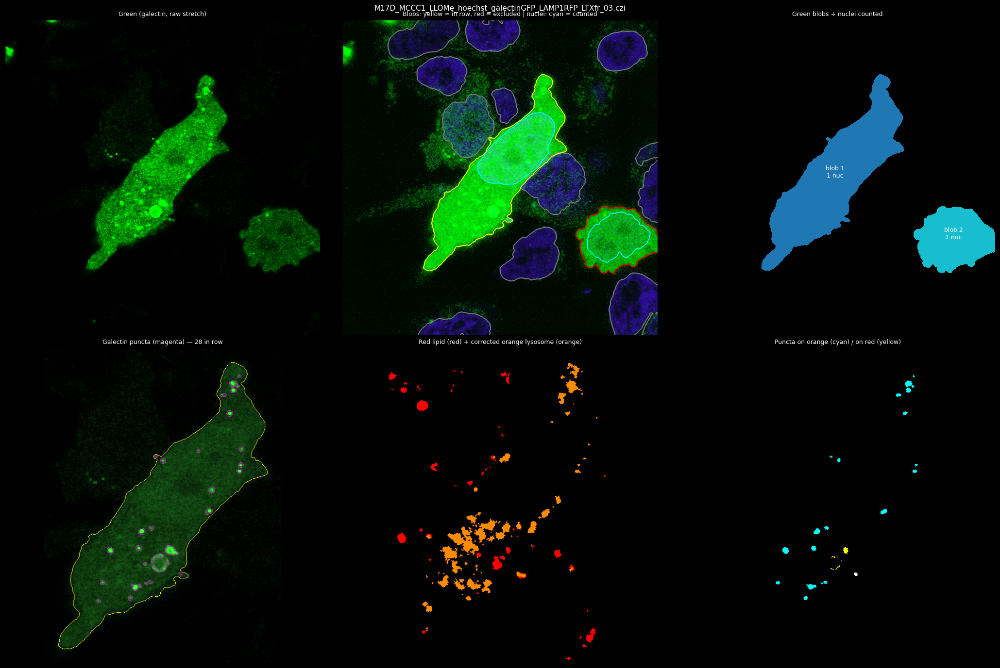


Processing: M17D_MCCC1_LLOMe_hoechst_galectinGFP_LAMP1RFP_LTXfr_04.czi


    green background 128 | blobs 1 | nuclei 17
    blob 1: 1 nucleus/nuclei, 48 puncta  -> kept


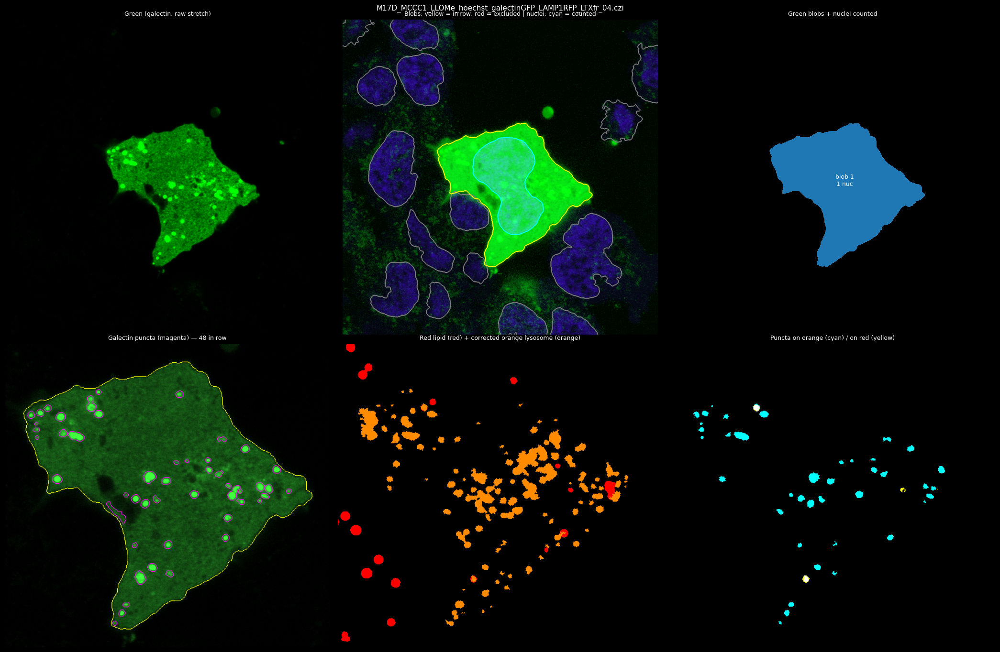


Processing: M17D_MCCC1_LLOMe_hoechst_galectinGFP_LAMP1RFP_LTXfr_05.czi


    green background 125 | blobs 1 | nuclei 13
    blob 1: 2 nucleus/nuclei, 28 puncta  -> kept


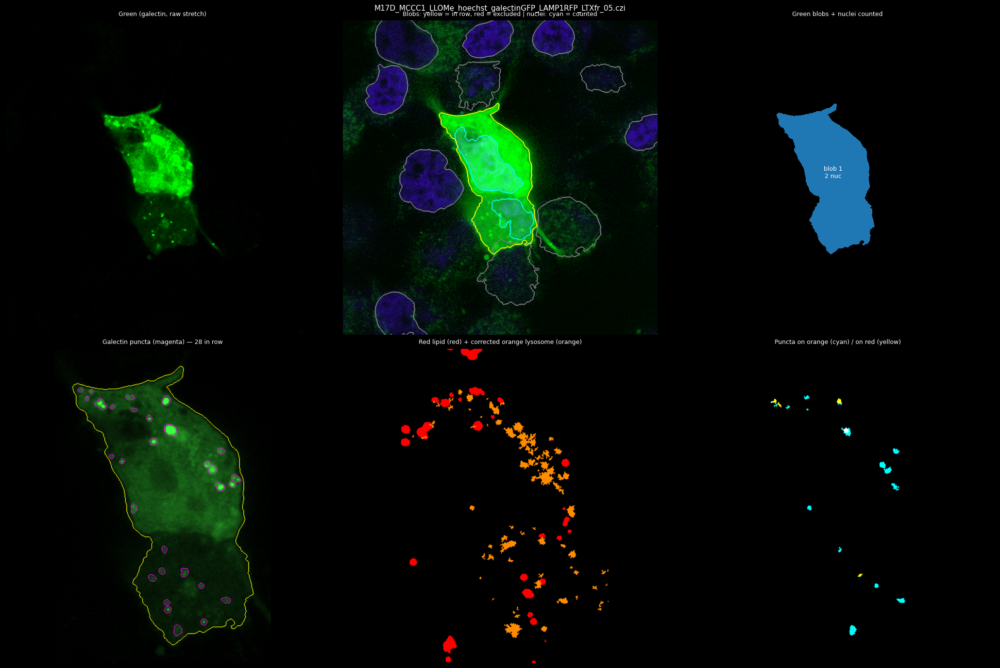


Processing: M17D_MCCC1_LLOMe_hoechst_galectinGFP_LAMP1RFP_LTXfr_06.czi


    green background 130 | blobs 1 | nuclei 24
    blob 1: 1 nucleus/nuclei, 14 puncta  -> kept


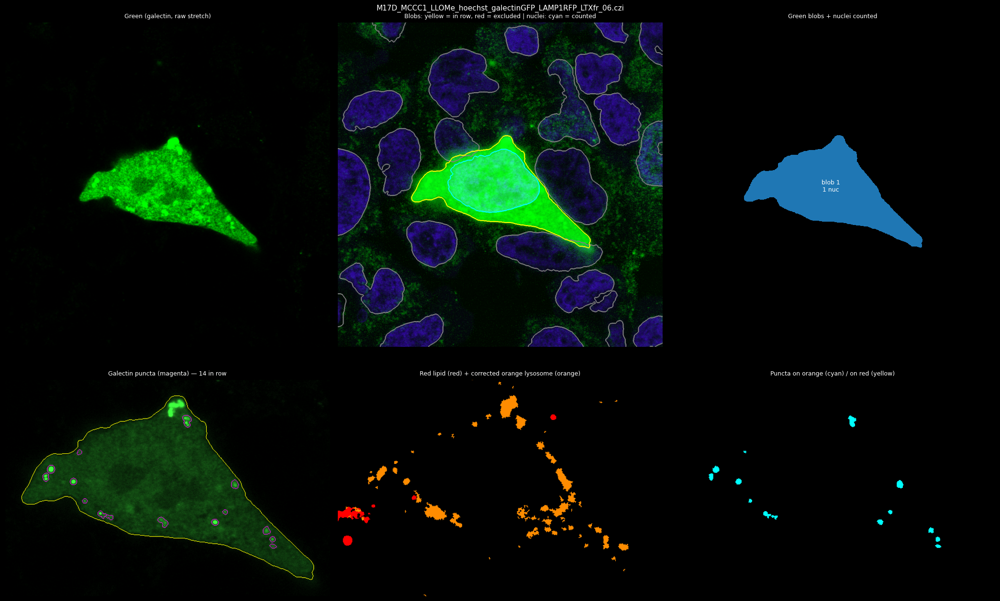


Processing: M17D_MCCC1_LLOMe_hoechst_galectinGFP_LAMP1RFP_LTXfr_07.czi


    green background 134 | blobs 2 | nuclei 19
    blob 1: 1 nucleus/nuclei, 5 puncta  -> EXCLUDED (touches image edge; no orange)
    blob 2: 1 nucleus/nuclei, 28 puncta  -> kept


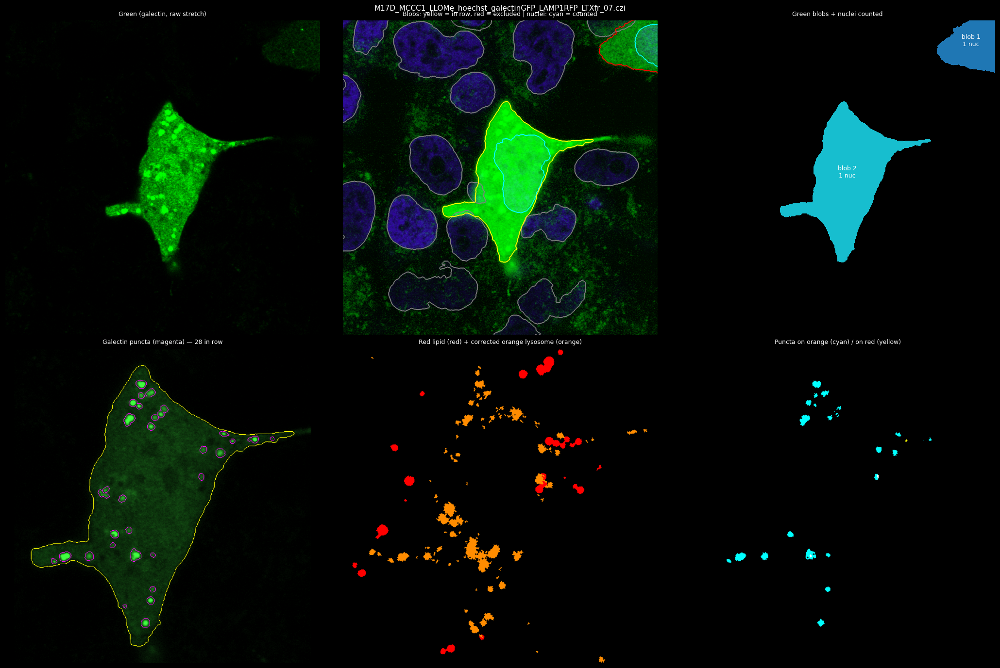


Processing: M17D_MCCC1_LLOMe_hoechst_galectinGFP_LAMP1RFP_LTXfr_08.czi


    green background 123 | blobs 1 | nuclei 12 | rescued nuclei {1: 1}
    blob 1: 1 nucleus/nuclei, 42 puncta  -> kept


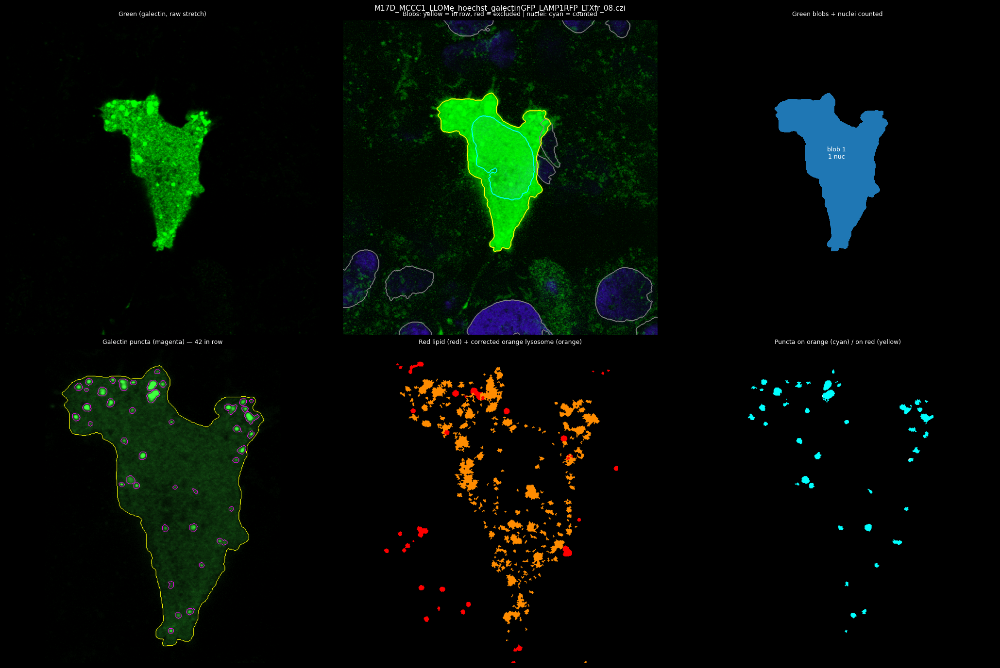


Processing: M17D_SCR_LLOMe_hoechst_galectinGFP_LAMP1RFP_LTXfr_01.czi


    green background 132 | blobs 1 | nuclei 20
    blob 1: 1 nucleus/nuclei, 2 puncta  -> kept


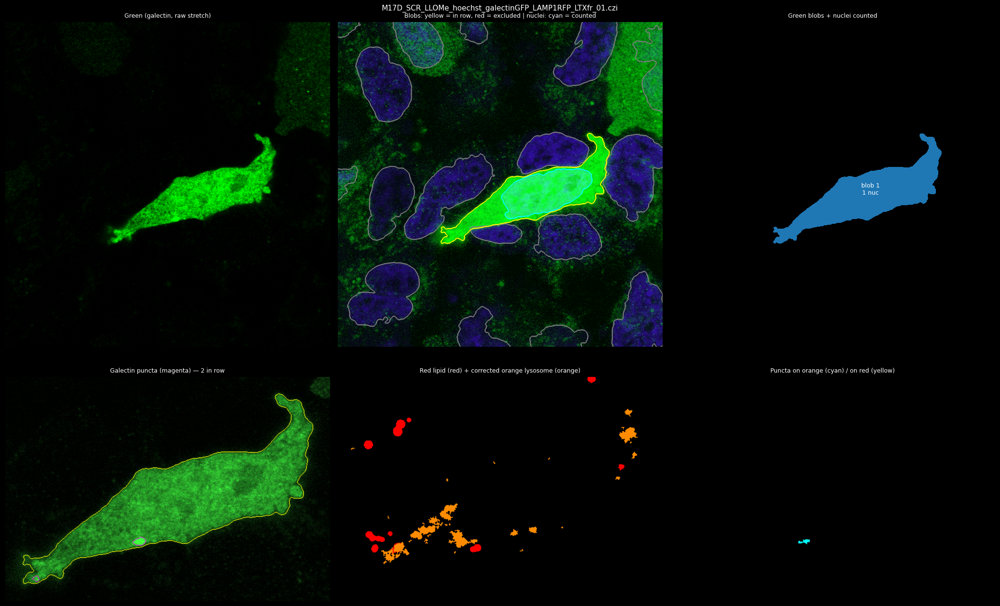


Processing: M17D_SCR_LLOMe_hoechst_galectinGFP_LAMP1RFP_LTXfr_02.czi


    green background 125 | blobs 2 | nuclei 20
    blob 1: 2 nucleus/nuclei, 10 puncta  -> kept
    blob 2: 1 nucleus/nuclei, 7 puncta  -> kept


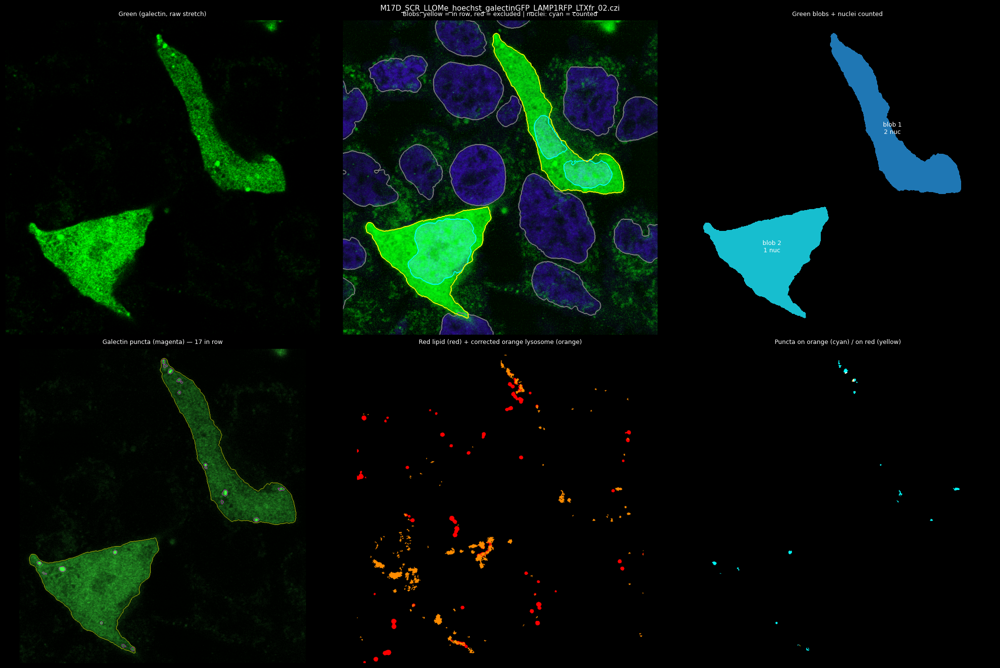


Processing: M17D_SCR_LLOMe_hoechst_galectinGFP_LAMP1RFP_LTXfr_03.czi


    green background 143 | blobs 3 | nuclei 18
    blob 1: 1 nucleus/nuclei, 9 puncta  -> EXCLUDED (touches image edge)
    blob 2: 1 nucleus/nuclei, 41 puncta  -> kept
    blob 3: 1 nucleus/nuclei, 13 puncta  -> kept


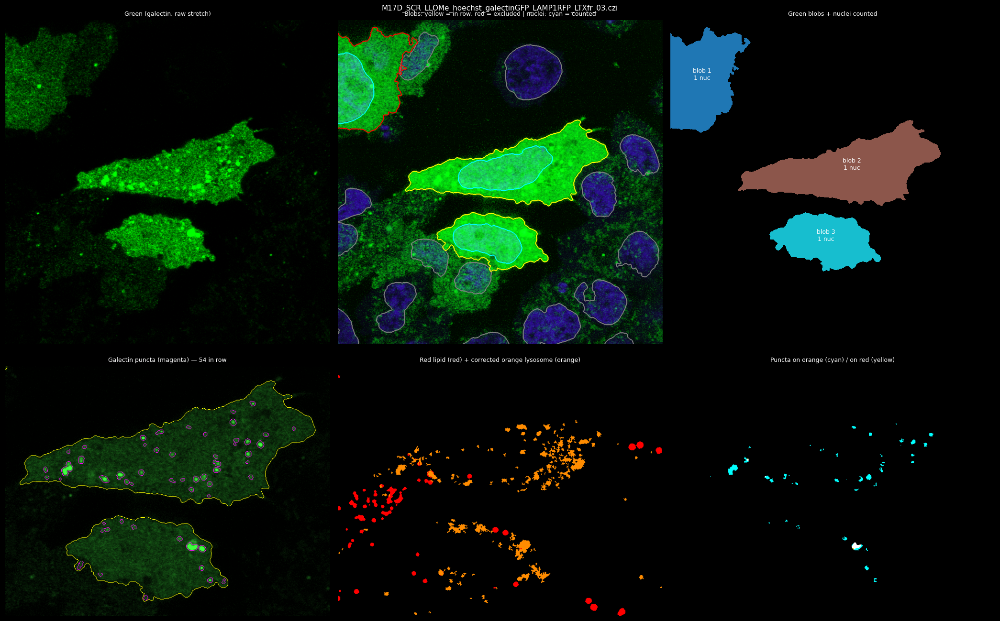


Processing: M17D_SCR_LLOMe_hoechst_galectinGFP_LAMP1RFP_LTXfr_04.czi


    green background 145 | blobs 1 | nuclei 17
    blob 1: 1 nucleus/nuclei, 7 puncta  -> kept


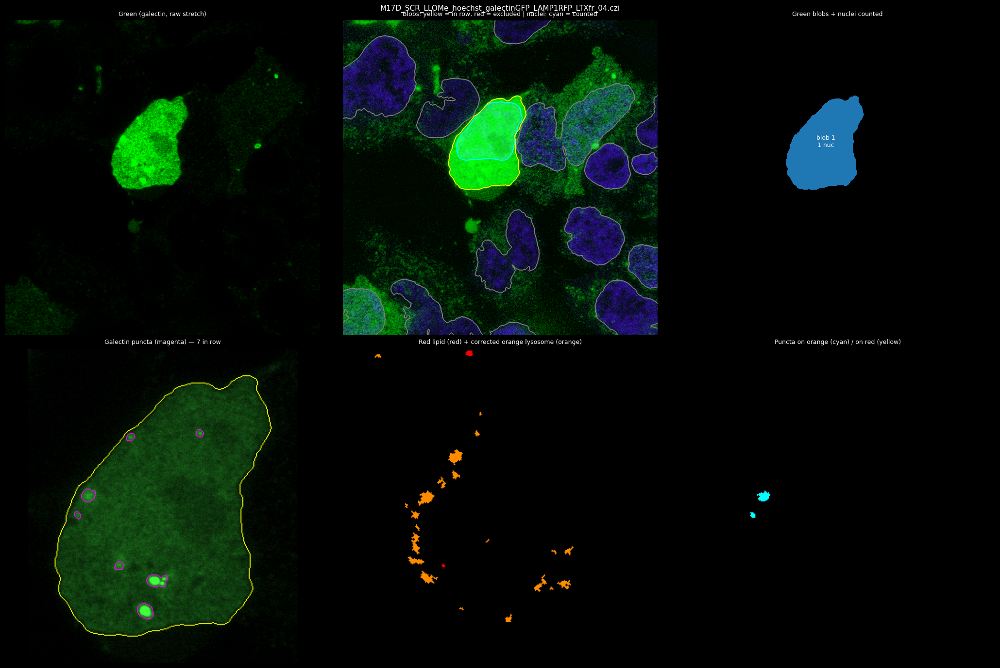

  -> 10 per-image row(s) saved to Results/galectin test images_galectin_alt1_green_blob_per_image.csv

[skip] './M17D_52926_siRNA_galectinGFP_LAMP1RFP_LipidTOXfr_hoechst' not found
[skip] './M17D_60426_siRNA_galectinGFP_LAMP1RFP_LipidTOXfr_hoechst' not found
[skip] './M17D_60526_siRNA_OA_Fed_galectinGFP_LAMP1RFP_LipidTOXfr_hoechst' not found
[skip] './M17D_60926_siRNA_OA_Fed_galectinGFP_LAMP1RFP_LipidTOXfr_Hoechst' not found
[skip] './M17D_61126_siRNA_galectinGFP_LAMP1RFP_LipidTOXfr_hoechst' not found
[skip] './M17D_61826_siRNA_galectinGFP_LAMP1RFP_LipidTOXfr_hoechst' not found
[skip] './M17D_61826_siRNA_OA_Fed_galectinGFP_LAMP1RFP_LipidTOXfr_Hoechst' not found


,Filename,N_Green_Cells,N_Nuclei,N_Blobs_Excluded,Green_Dots_per_Nucleus,Cell_Area_px,Cytoplasm_Area_px,Nucleus_Area_px,N_Green_Dots,Green_Dot_Area_px,...,N_Lysosomes,Lysosome_Area_px,N_Lipid_Droplets,LipidDroplet_Area_px,N_TriplePositive_Overlap,TriplePositive_Overlap_Area_px,N_TriplePositive_Touching,Green_Dot_IntDen,Green_Cytoplasm_IntDen,Green_EntireCell_IntDen
0,M17D_MCCC1_LLOMe_hoechst_galectinGFP_LAMP1RFP_...,1,1,1,28.0000,90275,58634,31641,28,2804,...,56,8462,19,1183,3,46,5,38528066.0,183640365.0,2.872106e+08
1,M17D_MCCC1_LLOMe_hoechst_galectinGFP_LAMP1RFP_...,1,1,0,48.0000,105456,66691,38765,48,5091,...,93,12678,9,1111,3,148,4,216798317.0,956823220.0,1.461026e+09
2,M17D_MCCC1_LLOMe_hoechst_galectinGFP_LAMP1RFP_...,1,2,0,14.0000,74653,43492,31161,28,2714,...,56,4643,21,2012,3,58,6,73061545.0,359923221.0,6.335921e+08
3,M17D_MCCC1_LLOMe_hoechst_galectinGFP_LAMP1RFP_...,1,1,0,14.0000,73020,36647,36373,14,1478,...,47,6127,1,54,0,0,1,40076295.0,317165125.0,6.327050e+08
4,M17D_MCCC1_LLOMe_hoechst_galectinGFP_LAMP1RFP_...,1,1,1,28.0000,75202,47277,27925,28,3658,...,74,6417,5,1112,2,32,3,101392915.0,347794572.0,5.411193e+08
5,M17D_MCCC1_LLOMe_hoechst_galectinGFP_LAMP1RFP_...,1,1,0,42.0000,78634,45407,33227,42,4146,...,174,13254,11,924,2,9,3,117279635.0,338257960.0,5.419394e+08
6,M17D_SCR_LLOMe_hoechst_galectinGFP_LAMP1RFP_LT...,1,1,0,2.0000,51404,25883,25521,2,247,...,21,3229,3,385,0,0,0,3222276.0,111100138.0,2.570811e+08
7,M17D_SCR_LLOMe_hoechst_galectinGFP_LAMP1RFP_LT...,2,3,0,5.6667,114955,68137,46818,17,1653,...,53,7352,14,2783,4,57,4,16897725.0,161663817.0,3.097469e+08
8,M17D_SCR_LLOMe_hoechst_galectinGFP_LAMP1RFP_LT...,2,2,1,27.0000,110334,71066,39268,54,4046,...,118,7744,15,1183,3,166,3,45613754.0,191489103.0,2.944006e+08
9,M17D_SCR_LLOMe_hoechst_galectinGFP_LAMP1RFP_LT...,1,1,0,7.0000,47159,21368,25791,7,732,...,19,1032,1,11,0,0,0,15751564.0,100583861.0,2.265397e+08


In [8]:
def analyze_folder(image_folder):
    """Process one folder and write one per-image CSV."""
    folder_tag = os.path.basename(os.path.normpath(image_folder))
    mask_dir = os.path.join(MASK_FOLDER, folder_tag)
    os.makedirs(mask_dir, exist_ok=True)
    image_files = sorted(glob.glob(os.path.join(image_folder, FILE_EXTENSION)))
    print(f"---------- {folder_tag}: {len(image_files)} image(s) ----------")
    rows = [r for r in (segment_one_image(f, mask_dir) for f in image_files) if r is not None]
    df = pd.DataFrame(rows)
    if len(df) and ((df["N_Nuclei"] == 0) | (df["Nucleus_Area_px"] == 0) | (df["Cytoplasm_Area_px"] == 0)).any():
        raise RuntimeError("A row with 0 nuclei / 0 nucleus area / 0 cytoplasm reached the table")
    out_csv = os.path.join(RESULTS_FOLDER, f"{folder_tag}_{IMAGE_CSV_SUFFIX}")
    df.to_csv(out_csv, index=False)
    print(f"  -> {len(df)} per-image row(s) saved to {out_csv}\n")
    return df


last_df = None
for image_folder in IMAGE_FOLDERS:
    if not os.path.isdir(image_folder):
        print(f"[skip] '{image_folder}' not found")
        continue
    last_df = analyze_folder(image_folder)
last_df

## Output summary

In [9]:
for csv_suffix in OUTPUT_SUFFIXES:
    csv_files = sorted(glob.glob(os.path.join(RESULTS_FOLDER, f"*_{csv_suffix}")))
    print(f"{len(csv_files)} file(s) *_{csv_suffix}:")
    for f in csv_files:
        try:
            n = len(pd.read_csv(f))
        except pd.errors.EmptyDataError:
            n = 0
        print(f"  {os.path.basename(f):90s} {n:>4d} row(s)")

1 file(s) *_galectin_alt1_green_blob_per_image.csv:
  galectin test images_galectin_alt1_green_blob_per_image.csv                                  10 row(s)
